In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

In [2]:
df = pd.read_json('suppliers_json.txt', dtype=False, convert_dates=False)
df.head()

,supplier_id,supplier_name,country,rating,contract_start_date,is_preferred
0,S001,"Baral, Din and Bhalla",NaN,4.3,2018-12-11,N
1,S002,Varughese Group,Germany,2.5,2019-03-02,False
2,S003,"Bahl, Mander and Chada",Vietnam,2.9,2022-03-12,False
3,S004,"Sinha, Subramaniam and Garde",China,9.4,2019-07-08,true
4,S005,Dhar-Gopal,Germany,4.5,2019-07-15,Y


In [3]:
df.shape

(19, 6)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   supplier_id          19 non-null     str    
 1   supplier_name        19 non-null     str    
 2   country              16 non-null     str    
 3   rating               19 non-null     float64
 4   contract_start_date  19 non-null     str    
 5   is_preferred         19 non-null     object 
dtypes: float64(1), object(1), str(4)
memory usage: 1.0+ KB


In [5]:
df.isnull().sum()

supplier_id            0
supplier_name          0
country                3
rating                 0
contract_start_date    0
is_preferred           0
dtype: int64

In [6]:
print(df.duplicated().sum())
print(df['supplier_id'].duplicated().sum())
df[df['supplier_id'].duplicated(keep=False)]

0
1


,supplier_id,supplier_name,country,rating,contract_start_date,is_preferred
3,S004,"Sinha, Subramaniam and Garde",China,9.4,2019-07-08,true
18,S004,"Amble, Prashad and Jha",Unknown,9.4,2019-07-08,true


In [7]:
for col in ['country', 'is_preferred']:
    print(df[col].value_counts(dropna=False))
    print()

country
Germany    6
Vietnam    5
NaN        3
China      2
India      2
Unknown    1
Name: count, dtype: int64

is_preferred
False    7
N        6
true     4
Y        1
True     1
Name: count, dtype: int64



In [8]:
df['rating'].describe()

count    19.000000
mean      4.589474
std       2.292474
min       1.600000
25%       2.950000
50%       4.100000
75%       4.950000
max       9.400000
Name: rating, dtype: float64

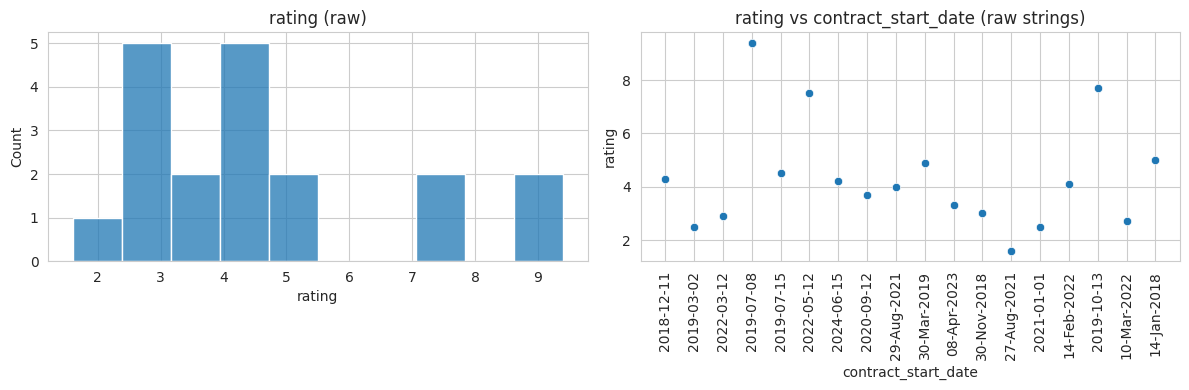

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['rating'], bins=10, ax=ax[0])
sns.scatterplot(data=df, x='contract_start_date', y='rating', ax=ax[1])
ax[0].set_title('rating (raw)')
ax[1].set_title('rating vs contract_start_date (raw strings)')
ax[1].tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

In [10]:
df[df['rating'] > 5][['supplier_id', 'supplier_name', 'rating']]

,supplier_id,supplier_name,rating
3,S004,"Sinha, Subramaniam and Garde",9.4
5,S006,"Lalla, Ganesh and Oommen",7.5
15,S016,Chacko LLC,7.7
18,S004,"Amble, Prashad and Jha",9.4


In [11]:
def parse_date(x):
    if pd.isna(x):
        return pd.NaT
    x = str(x).strip()
    if x == '' or x.lower() == 'unknown':
        return pd.NaT
    if '/' in x:
        a, b, c = [int(i) for i in x.split('/')]
        if a > 12:
            return pd.Timestamp(year=c, month=b, day=a)
        if b > 12:
            return pd.Timestamp(year=c, month=a, day=b)
        return pd.Timestamp(year=c, month=b, day=a)
    if len(x) == 10 and x[4] == '-':
        return pd.to_datetime(x, format='%Y-%m-%d')
    return pd.to_datetime(x, format='%d-%b-%Y')


def is_ambiguous(x):
    if pd.isna(x) or '/' not in str(x):
        return False
    a, b, c = [int(i) for i in str(x).split('/')]
    return a <= 12 and b <= 12 and a != b

In [12]:
before = len(df)
df['supplier_name'] = df['supplier_name'].str.strip()
df['country'] = df['country'].replace('Unknown', np.nan)

In [13]:
df = df.sort_values(['supplier_id', 'country'], na_position='last')
df = df.drop_duplicates('supplier_id', keep='first').reset_index(drop=True)
print(before, '->', len(df))
df['supplier_id'].duplicated().sum()

19 -> 18


np.int64(0)

In [14]:
df['country'] = df['country'].fillna('Unknown')
df['country'].value_counts()

country
Germany    6
Vietnam    5
Unknown    3
China      2
India      2
Name: count, dtype: int64

In [15]:
bool_map = {'y': True, 'true': True, 'n': False, 'false': False}
df['is_preferred'] = df['is_preferred'].astype(str).str.lower().map(bool_map)
print(df['is_preferred'].isnull().sum())
df['is_preferred'].value_counts()

0


is_preferred
False    13
True      5
Name: count, dtype: int64

In [16]:
df['contract_start_date'] = df['contract_start_date'].apply(parse_date)
df['contract_start_date'].describe()

count                     18
mean     2020-10-25 20:00:00
min      2018-01-14 00:00:00
25%      2019-04-24 00:00:00
50%      2020-11-06 12:00:00
75%      2022-03-04 00:00:00
max      2024-06-15 00:00:00
Name: contract_start_date, dtype: object

In [17]:
df['rating_raw'] = df['rating']
df['rating_5pt'] = np.where(df['rating_raw'] > 5, df['rating_raw'] / 2, df['rating_raw']).round(2)
df = df.drop(columns='rating')
df[['supplier_id', 'rating_raw', 'rating_5pt']].sort_values('rating_raw', ascending=False).head(8)

,supplier_id,rating_raw,rating_5pt
3,S004,9.4,4.70
15,S016,7.7,3.85
5,S006,7.5,3.75
17,S018,5.0,5.00
9,S010,4.9,4.90
4,S005,4.5,4.50
0,S001,4.3,4.30
6,S007,4.2,4.20


In [18]:
print(df['rating_5pt'].min(), df['rating_5pt'].max())
print((df['contract_start_date'] > pd.Timestamp.today()).sum())

1.6 5.0
0


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   supplier_id          18 non-null     str           
 1   supplier_name        18 non-null     str           
 2   country              18 non-null     str           
 3   contract_start_date  18 non-null     datetime64[us]
 4   is_preferred         18 non-null     bool          
 5   rating_raw           18 non-null     float64       
 6   rating_5pt           18 non-null     float64       
dtypes: bool(1), datetime64[us](1), float64(2), str(3)
memory usage: 1014.0 bytes


In [20]:
df.isnull().sum()

supplier_id            0
supplier_name          0
country                0
contract_start_date    0
is_preferred           0
rating_raw             0
rating_5pt             0
dtype: int64

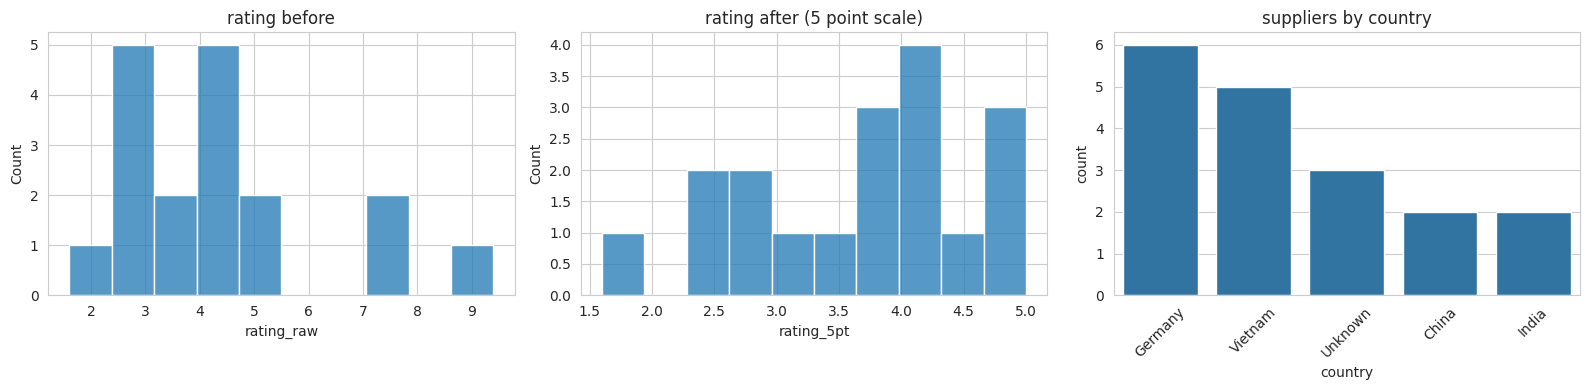

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['rating_raw'], bins=10, ax=ax[0])
sns.histplot(df['rating_5pt'], bins=10, ax=ax[1])
sns.countplot(data=df, x='country', order=df['country'].value_counts().index, ax=ax[2])
ax[0].set_title('rating before')
ax[1].set_title('rating after (5 point scale)')
ax[2].set_title('suppliers by country')
ax[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

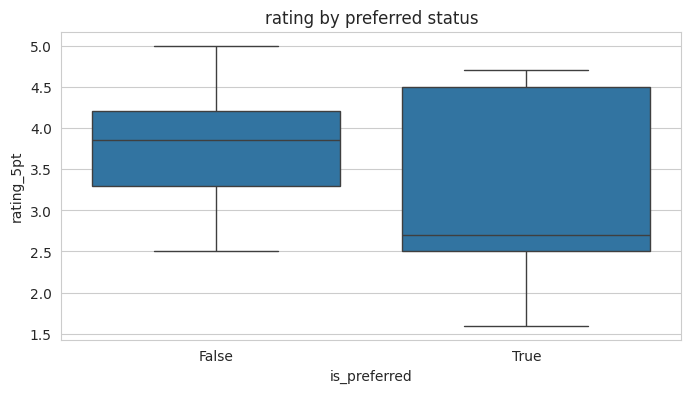

In [22]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='is_preferred', y='rating_5pt')
plt.title('rating by preferred status')
plt.show()

In [23]:
df.to_csv('suppliers_clean.csv', index=False)
df

,supplier_id,supplier_name,country,contract_start_date,is_preferred,rating_raw,rating_5pt
0,S001,"Baral, Din and Bhalla",Unknown,2018-12-11,False,4.3,4.30
1,S002,Varughese Group,Germany,2019-03-02,False,2.5,2.50
2,S003,"Bahl, Mander and Chada",Vietnam,2022-03-12,False,2.9,2.90
3,S004,"Sinha, Subramaniam and Garde",China,2019-07-08,True,9.4,4.70
4,S005,Dhar-Gopal,Germany,2019-07-15,True,4.5,4.50
5,S006,"Lalla, Ganesh and Oommen",Germany,2022-05-12,False,7.5,3.75
6,S007,"Biswas, Karpe and Radhakrishnan",Unknown,2024-06-15,False,4.2,4.20
7,S008,Babu and Sons,India,2020-09-12,False,3.7,3.70
8,S009,"Saini, Doctor and Char",Germany,2021-08-29,False,4.0,4.00
9,S010,"Barad, Wali and Thakur",Germany,2019-03-30,False,4.9,4.90
